# 03 · Pipeline: de FS a ML (objetivo y partición temporal)

**Objetivo de este cuaderno:** construir la tabla con la que se entrena el modelo: `ml_dataset` = **variables** (de FS) + **objetivo** (`y`) + **partición**.

### El objetivo (`y`): lo que queremos predecir
`y = 1` si el cliente compra al menos una vez en la **ventana** `[corte, corte + 90 días)`; `y = 0` si no.
Es la única parte del pipeline que mira **el futuro** del corte, y es correcto: es la respuesta que el modelo debe aprender a anticipar.
Las variables (cuaderno 02) miran el pasado; el objetivo mira el futuro. Nunca al revés.

```
  variables (pasado)            objetivo (futuro)
  ──────────────────────┤ corte ├──── 90 días ────┤──────►
                                 ¿compra aquí? → y
```

### La partición: con qué se entrena y con qué se evalúa
Un modelo se evalúa con datos que **no vio** al entrenar; si no, solo sabríamos si memoriza. Se usan tres grupos:

| Partición | Para qué | Cortes |
|---|---|---|
| **train** (entrenamiento) | El modelo aprende aquí | 2010-06-01 a 2010-12-01, mensuales |
| **valid** (validación) | Comparar modelos y elegir el mejor | 2011-03-01 |
| **test** (prueba) | Estimar, **una sola vez**, cómo funcionará el elegido | 2011-06-01 y 2011-09-01 |

**La partición es temporal, nunca aleatoria.** En producción el modelo se entrena con el pasado y predice el futuro. Si repartiéramos las filas al azar,
el modelo entrenaría con fotos de 2011 y se evaluaría con fotos de 2010: estaría usando el futuro para predecir el pasado, otra forma de fuga.
Además, las **ventanas del objetivo no se solapan** entre particiones: la ventana del último corte de train termina justo donde empieza valid.

**Entra:** FS y MASTER. **Sale:** `ml_particiones` y `ml_dataset` en `curso.db`, y la figura `reports/figures/ml_ventanas.png`.

## Train, valid y test en un dibujo

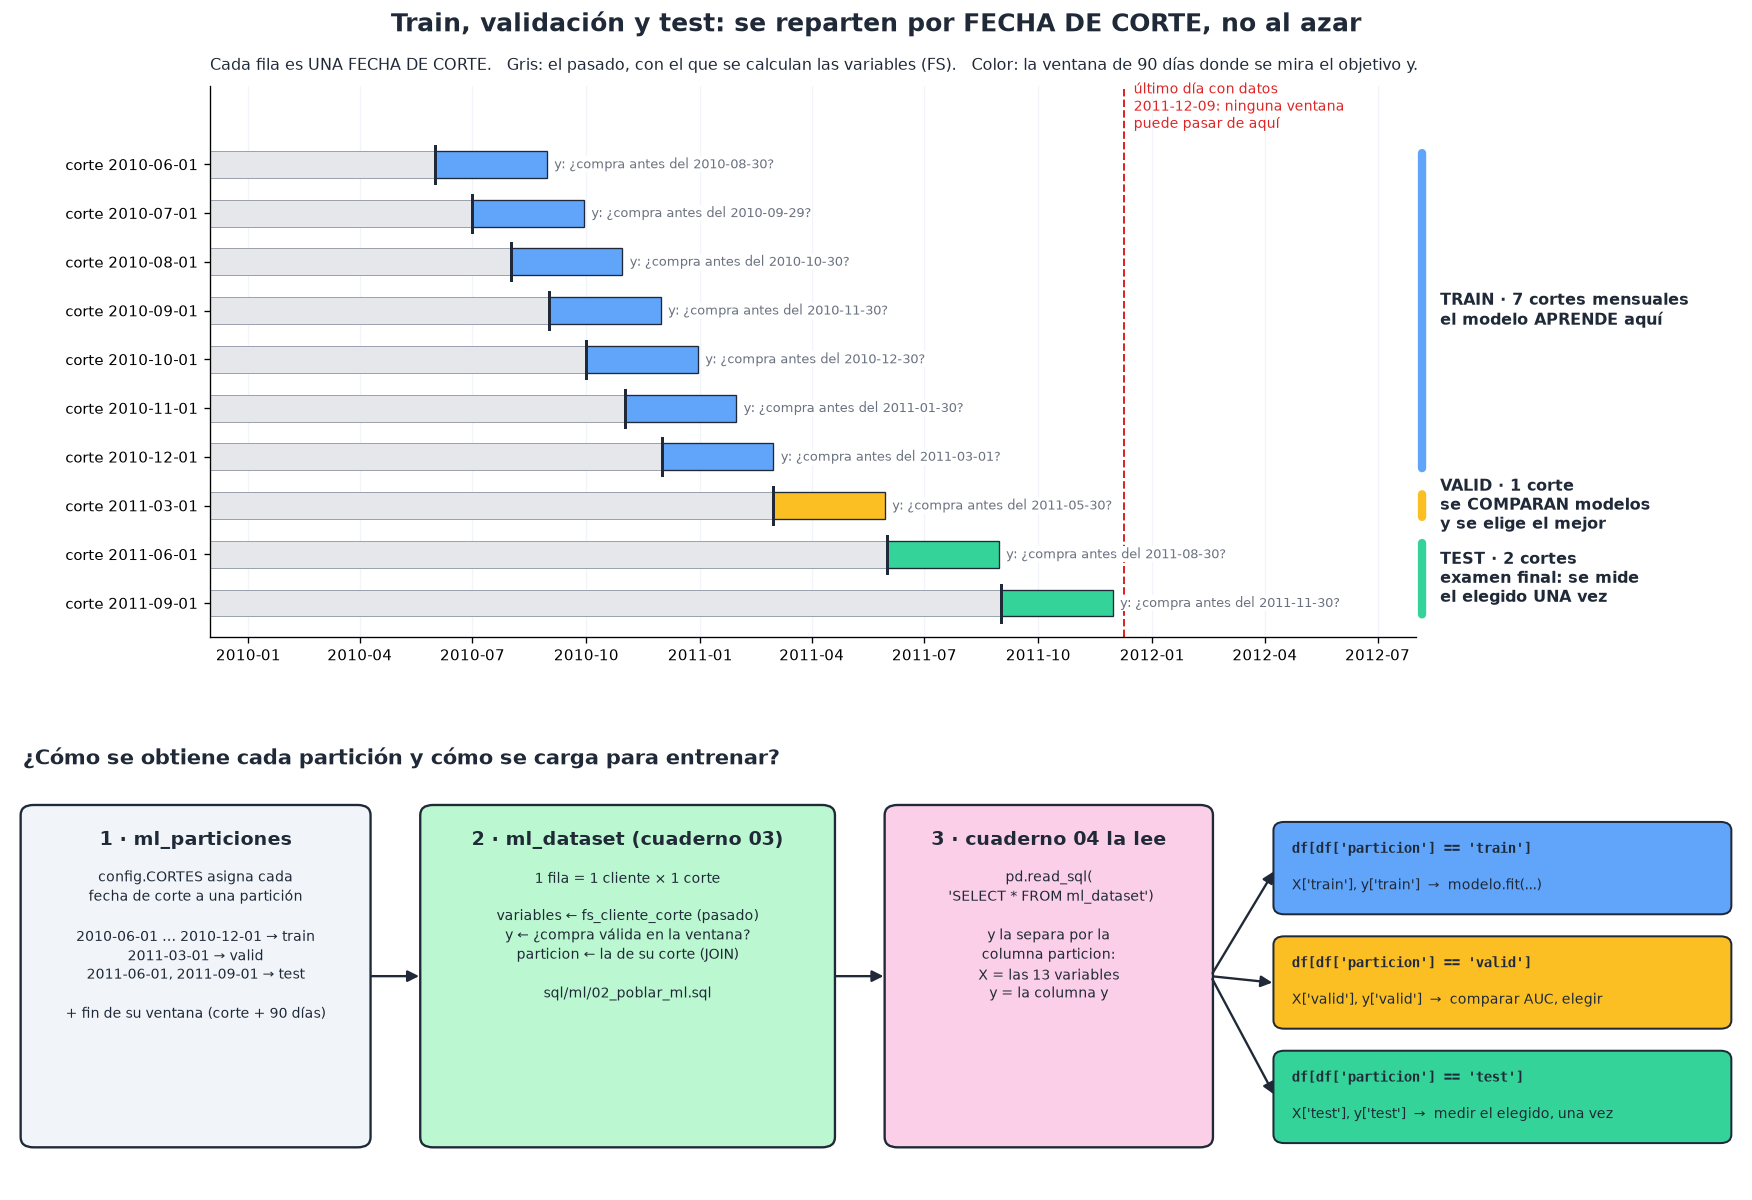

**Cómo leer la parte de arriba.** Cada fila es **una fecha de corte**. La barra gris es el **pasado** de ese corte: con él se calcularon las variables (cuaderno 02).
La barra de color es la **ventana de 90 días** que empieza en el corte: ahí se mira si el cliente compró (`y`). El color dice a qué partición pertenece el corte.
Fíjate en tres cosas:
1. Las ventanas de **train** (azul) terminan, como muy tarde, el día en que empieza la de **valid** (amarillo), y la de valid antes de que empiece **test** (verde): nunca se solapan.
2. **Test es lo más reciente**: el modelo se examina con el periodo más parecido al «futuro» en el que se usará.
3. Ninguna ventana pasa del **último día con datos** (línea roja): si pasara, faltarían compras por registrar y `y` saldría falsamente en 0.

**Una analogía.** *Train* son los ejercicios con los que estudias; *valid*, el simulacro con el que decides qué método de estudio funciona mejor;
*test*, el examen final, que se hace **una sola vez** y no se repite hasta aprobar. Si miraras el examen para decidir cómo estudiar, la nota ya no diría nada.

**Cómo se obtiene cada partición** (parte de abajo del dibujo):
1. `CORTES` (en la celda de parámetros y en `ia_mlops/config.py`) asigna **cada fecha de corte** a una partición. Esa es la única decisión: el resto se deriva.
2. `ml_particiones` guarda esa asignación y el fin de la ventana de cada corte.
3. `ml_dataset` se construye uniendo (`JOIN`) cada fila de FS con su corte en `ml_particiones`: así **cada fila hereda la partición de su fecha de corte**.
4. El cuaderno 04 lee `ml_dataset` entero y lo separa por la columna `particion`. No hay ningún sorteo ni ninguna semilla aleatoria.

**¿Puede un cliente estar en train y en test?** Sí, y es lo esperado: un cliente tiene una foto en cada corte (en diciembre de 2010, en marzo de 2011…).
Son momentos distintos, con variables distintas y ventanas que no se solapan. Así se usará el modelo en la realidad: con clientes que ya conocemos, en fechas futuras.

In [1]:
# Parámetros. None usa las rutas por defecto del proyecto (o las variables de entorno CURSO_DB y CURSO_REPORTES).
RUTA_DB = None
RUTA_REPORTES = None
VENTANA_OBJETIVO_DIAS = 90
CORTES = {
    'train': ['2010-06-01', '2010-07-01', '2010-08-01', '2010-09-01', '2010-10-01', '2010-11-01', '2010-12-01'],
    'valid': ['2011-03-01'],
    'test': ['2011-06-01', '2011-09-01'],
}

In [2]:
import os, sqlite3, sys
from pathlib import Path

import pandas as pd

pd.set_option('display.width', 150, 'display.max_columns', 30)

# Carpeta del proyecto: la que contiene «sql» y «pyproject.toml».
RAIZ = Path.cwd().resolve()
while not ((RAIZ / 'sql').exists() and (RAIZ / 'pyproject.toml').exists()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
SQL = RAIZ / 'sql'
DB = Path(RUTA_DB or os.environ.get('CURSO_DB') or RAIZ / 'data' / 'processed' / 'curso.db')
DB.parent.mkdir(parents=True, exist_ok=True)

con = sqlite3.connect(DB)
con.execute('PRAGMA foreign_keys = ON')


def ejecutar_script(archivo):
    """Ejecuta un archivo .sql de la carpeta sql/ (puede tener varias sentencias)."""
    con.executescript((SQL / archivo).read_text(encoding='utf-8'))
    con.commit()


def escalar(consulta, parametros=None):
    fila = con.execute(consulta, parametros or {}).fetchone()
    return None if fila is None else fila[0]


print('Proyecto:', RAIZ)
print('Base de datos:', DB)
REPORTES = Path(RUTA_REPORTES or os.environ.get('CURSO_REPORTES') or RAIZ / 'reports')
(REPORTES / 'figures').mkdir(parents=True, exist_ok=True)

Proyecto: C:\bk\HC-Cursos\curso-ml-ia-desarrollo-produccion\04-Proyecto-Base
Base de datos: C:\bk\HC-Cursos\curso-ml-ia-desarrollo-produccion\04-Proyecto-Base\data\processed\curso.db


## 1. Crear las tablas y registrar las particiones
`ml_particiones` guarda, para cada fecha de corte, su partición y dónde termina su ventana.
Antes de registrar un corte se comprueba que **su ventana cabe en los datos**: si la ventana terminara después del último día con datos,
muchos clientes aparecerían como «no compró» solo porque aún no había datos. Ese objetivo estaría **incompleto y sesgado**, y el cuaderno se detiene.

In [3]:
ejecutar_script('ml/01_crear_ml.sql')
ultimo_dia = escalar('SELECT MAX(fecha_factura) FROM master_facturas')[:10]
print('Último día con datos:', ultimo_dia)
for particion, cortes in CORTES.items():
    for corte in cortes:
        fin = escalar("SELECT date(:c, '+' || :d || ' day')", {'c': corte, 'd': VENTANA_OBJETIVO_DIAS})
        assert fin <= ultimo_dia, f'El corte {corte} necesita datos hasta {fin}, pero el último día con datos es {ultimo_dia}.'
        con.execute('INSERT INTO ml_particiones (fecha_corte, particion, ventana_dias, fin_ventana) VALUES (?,?,?,?)',
                    (corte, particion, VENTANA_OBJETIVO_DIAS, fin))
con.commit()
pd.read_sql('SELECT * FROM ml_particiones ORDER BY fecha_corte', con)

Último día con datos: 2011-12-09


,fecha_corte,particion,ventana_dias,fin_ventana
0,2010-06-01,train,90,2010-08-30
1,2010-07-01,train,90,2010-09-29
2,2010-08-01,train,90,2010-10-30
3,2010-09-01,train,90,2010-11-30
4,2010-10-01,train,90,2010-12-30
5,2010-11-01,train,90,2011-01-30
6,2010-12-01,train,90,2011-03-01
7,2011-03-01,valid,90,2011-05-30
8,2011-06-01,test,90,2011-08-30
9,2011-09-01,test,90,2011-11-30


## 2. Poblar ML
`sql/ml/02_poblar_ml.sql` une (`JOIN`) cada fila de FS con su partición y calcula `y` buscando ventas válidas del cliente **dentro de la ventana**.
La **tasa de recompra** (porcentaje de `y = 1`) de cada partición es la **tasa base**: lo que acertaría alguien que dijera siempre «sí».
Observa que cambia entre periodos: es la primera pista de la **deriva** (el comportamiento cambia con el tiempo), que veremos en S5.

In [4]:
ejecutar_script('ml/02_poblar_ml.sql')
pd.read_sql("""SELECT particion, COUNT(*) AS filas, SUM(y) AS recompran, ROUND(100.0 * AVG(y), 1) AS tasa_recompra_pct
               FROM ml_dataset GROUP BY particion ORDER BY MIN(fecha_corte)""", con)

,particion,filas,recompran,tasa_recompra_pct
0,train,626,318,50.8
1,valid,114,52,45.6
2,test,250,101,40.4


### ¿Cómo se cargan estas particiones para entrenar?
Exactamente como lo hará el cuaderno 04: se lee `ml_dataset` **entero** y se separa por la columna `particion`. En notación de aprendizaje automático,
**`X`** son las variables (lo que ve el modelo) e **`y`** el objetivo (lo que debe predecir). Cada partición tiene su propio `X` y su propio `y`.

In [5]:
# Así carga el cuaderno 04 las particiones: lee ml_dataset y lo separa por la columna «particion». No hay sorteo.
columnas_fijas = ('cliente_id', 'fecha_corte', 'particion', 'y')
datos = pd.read_sql('SELECT * FROM ml_dataset', con)
variables = [c for c in datos.columns if c not in columnas_fijas]
X = {p: datos.loc[datos['particion'] == p, variables] for p in CORTES}
y = {p: datos.loc[datos['particion'] == p, 'y'] for p in CORTES}
print('Variables (columnas de X):', len(variables))
pd.DataFrame({'filas de X': {p: len(X[p]) for p in X}, 'clientes distintos': {p: datos.loc[datos['particion'] == p, 'cliente_id'].nunique() for p in X},
              'cortes': {p: len(CORTES[p]) for p in X}, 'tasa de y = 1': {p: round(y[p].mean(), 3) for p in y}})

Variables (columnas de X): 13


,filas de X,clientes distintos,cortes,tasa de y = 1
train,626,109,7,0.508
valid,114,114,1,0.456
test,250,131,2,0.404


Un **mismo cliente** visto en todos sus cortes. Observa cómo cambian sus variables de una foto a otra (la recencia, la frecuencia, el gasto) y cómo cambia su `y`:
cada fila es un ejemplo distinto para el modelo, y cada una pertenece a la partición de su fecha.

In [6]:
cliente = int(escalar('SELECT cliente_id FROM ml_dataset GROUP BY cliente_id HAVING COUNT(DISTINCT particion) = 3 ORDER BY COUNT(*) DESC, cliente_id LIMIT 1'))
print('Cliente', cliente)
pd.read_sql('SELECT fecha_corte, particion, recencia_dias, frecuencia, monto_total, frecuencia_90d, y FROM ml_dataset '
            'WHERE cliente_id = :c ORDER BY fecha_corte', con, params={'c': cliente})

Cliente 12369


,fecha_corte,particion,recencia_dias,frecuencia,monto_total,frecuencia_90d,y
0,2010-06-01,train,84,1,308.32,1,0
1,2010-07-01,train,114,1,308.32,0,1
2,2010-08-01,train,145,1,308.32,0,1
3,2010-09-01,train,176,1,308.32,0,1
4,2010-10-01,train,14,2,1367.80,1,1
5,2010-11-01,train,9,3,1511.15,2,0
6,2010-12-01,train,39,3,1511.15,2,0
7,2011-03-01,valid,129,3,1511.15,0,0
8,2011-06-01,test,221,3,1511.15,0,0
9,2011-09-01,test,313,3,1511.15,0,0


## 3. Ventanas del objetivo de cada corte
Cada barra es la ventana de 90 días de un corte. Los colores son las particiones. Las ventanas de train pueden solaparse entre sí (son del mismo periodo),
pero **no se solapan** con las de valid ni test.

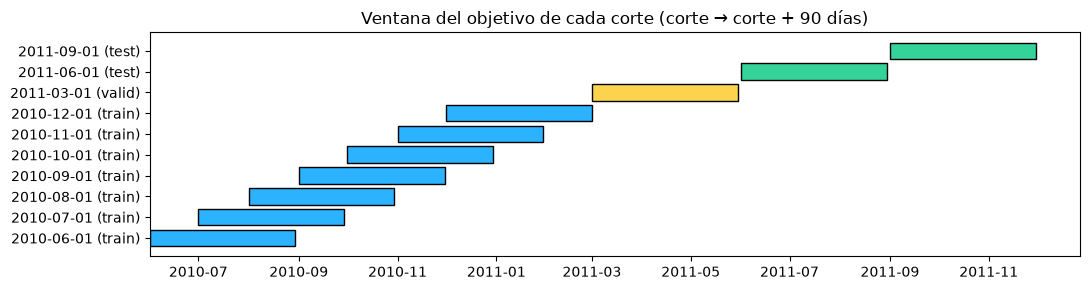

In [7]:
import matplotlib
matplotlib.use('Agg') if os.environ.get('CURSO_SIN_PANTALLA') else None
import matplotlib.pyplot as plt

p = pd.read_sql('SELECT * FROM ml_particiones ORDER BY fecha_corte', con)
colores = {'train': '#2bb3ff', 'valid': '#fcd34d', 'test': '#34d399'}
fig, ax = plt.subplots(figsize=(11, 3))
for i, r in p.iterrows():
    ini, fin = pd.Timestamp(r.fecha_corte), pd.Timestamp(r.fin_ventana)
    ax.barh(i, (fin - ini).days, left=ini, color=colores[r.particion], edgecolor='k')
ax.set_yticks(range(len(p)))
ax.set_yticklabels([f'{r.fecha_corte} ({r.particion})' for r in p.itertuples()])
ax.set_title('Ventana del objetivo de cada corte (corte → corte + 90 días)')
plt.tight_layout()
fig.savefig(REPORTES / 'figures' / 'ml_ventanas.png', dpi=110)
plt.show()

## 4. Comprobar el objetivo con pandas
Recalculamos `y` para una muestra de filas, mirando las facturas **dentro de la ventana**, y comparamos con lo que calculó SQL.

In [8]:
ml = pd.read_sql('SELECT cliente_id, fecha_corte, y FROM ml_dataset', con).sample(min(200, escalar('SELECT COUNT(*) FROM ml_dataset')), random_state=0)
ventas = pd.read_sql("""SELECT f.cliente_id, f.fecha_factura FROM master_lineas l JOIN master_facturas f ON f.factura_id = l.factura_id
                        WHERE l.es_venta_valida = 1 AND f.cliente_id IS NOT NULL""", con)
ventas['fecha'] = pd.to_datetime(ventas['fecha_factura'])


def y_pandas(fila):
    ini = pd.Timestamp(fila.fecha_corte)
    fin = ini + pd.Timedelta(days=VENTANA_OBJETIVO_DIAS)
    return int(((ventas['cliente_id'] == fila.cliente_id) & (ventas['fecha'] >= ini) & (ventas['fecha'] < fin)).any())


coincidencia = (ml.apply(y_pandas, axis=1) == ml['y']).mean()
print(f'Coincidencia entre SQL y pandas en {len(ml)} filas: {coincidencia:.0%}')
assert coincidencia == 1.0

Coincidencia entre SQL y pandas en 200 filas: 100%


In [9]:
con.close()
print('Listo: ML construida en', DB)

Listo: ML construida en C:\bk\HC-Cursos\curso-ml-ia-desarrollo-produccion\04-Proyecto-Base\data\processed\curso.db


## Resumen
- `ml_dataset` tiene una fila por cliente y corte, con sus 13 variables, su objetivo `y` y su partición.
- El objetivo mira 90 días hacia delante; las variables, solo hacia atrás. La partición es **por tiempo** y sus ventanas no se solapan.

**Siguiente:** el cuaderno **04** entrena y compara modelos con estos datos y registra cada intento en MLflow.

## Para practicar
1. Cambia `VENTANA_OBJETIVO_DIAS` a 60 y vuelve a ejecutar el cuaderno desde el principio. ¿Cómo cambia la tasa de recompra? Observa que cambian también los cortes posibles.
2. ¿Qué pasaría si la partición fuera **aleatoria**? Escribe qué fuga de información introduciría.